<div style="background-color:#EFF5FF; padding:14px; border-radius:10px; border-left:8px solid #009E91;">

<h2 style="margin-bottom:0;"><b>Notebook 3: Vectorization and Modelling</b></h2>

# Table of Contents: Notebook 3 - Feature Engineering & Predictive Modeling

**1. Introduction**
*(O texto introdutório que já criámos na resposta anterior)*

**2. Feature Extraction (Vectorization)**
*(Aqui aplicamos a matéria do Notebook 3 do teu professor, testando os dois métodos e usando Unigramas e Bigramas)*
* 2.1. Vectorizing with Bag-of-Words (CountVectorizer)
* 2.2. Vectorizing with Term Frequency-Inverse Document Frequency (TF-IDF)
* 2.3. Vector Spaces Comparison (BoW vs. TF-IDF)

**3. Data Splitting & Handling Class Imbalance**
*(Aqui resolvemos o problema da Pop dominar o dataset)*
* 3.1. Train/Test Split
* 3.2. Addressing Imbalance (SMOTE / Class Weights / Undersampling)

**4. Predictive Modeling (Machine Learning)**
*(Onde os modelos tentam adivinhar o género musical)*
* 4.1. Baseline Model: Multinomial Naive Bayes
* 4.2. Advanced Model 1: Logistic Regression 
* 4.3. Advanced Model 2: Support Vector Machines (SVM) / Random Forest

**5. Model Evaluation & Comparison**
*(Avaliação baseada no que discutiste: evitar Accuracy cega)*
* 5.1. Classification Reports (Precision, Recall, Macro F1-Score)
* 5.2. Confusion Matrices Analysis (Genre-by-Genre Performance)

**6. Conclusion & Best Model Selection**



### **1. Introduction, Imports and Libraries**

In the previous notebook, we focused entirely on preparing our dataset. **We are now ready to transition into the machine learning phase**.

The first major challenge in this notebook is feature engineering. Since machine learning algorithms **cannot interpret raw text, we need to translate our processed lyrics into a mathematical format**. To achieve this, we will apply vectorization techniques, primarily **TF-IDF** (Term Frequency-Inverse Document Frequency), which will assign numerical weights to words based on their importance and rarity across the different musical genres.

After vectorizing the text, we will address the significant class imbalance we identified during the Exploratory Data Analysis. We will explore strategies such as class weights or resampling to create a more balanced learning environment. Finally, we will **train several classification models and evaluate their performance** using robust metrics like Precision, Recall, and the Macro F1-Score, ensuring our models can accurately predict genres across the entire musical spectrum.

In [5]:
import pickle

with open('train_dataset_preprocessed.pkl', 'rb') as f:
    train_dataset = pickle.load(f)

In [23]:
import re
import os
import pickle
import nltk

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import defaultdict
from collections import Counter

from wordcloud import WordCloud

In [12]:
# Exemplo de como aplicas a função atualizada no teu Notebook de limpeza:
from utils.processing_pipeline_for_classification import tokenization_processing


train_dataset['lyrics_processed_for_classification'] = train_dataset['lyrics_processed_for_classification'].apply(
    lambda text: tokenization_processing(
        text, 
        print_output=False, 
        pos_tagging=True, 
        no_stopwords=True, 
        lemmatized=True,
        tokenized_output=False 
    )
)

TypeError: expected string or bytes-like object, got 'tuple'

### **Bag of words**

In [7]:
# o que o stor
bow_vectorizer = CountVectorizer(ngram_range=(1,2), token_pattern=r"(?u)\b\w+\b")
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,2), token_pattern=r"(?u)\b\w+\b")

In [20]:
import ast
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 1. Função para extrair e juntar as palavras numa única string de texto
def join_tokens_for_sklearn(val):
    if isinstance(val, str):
        try:
            val = ast.literal_eval(val)
        except:
            pass
            
    if isinstance(val, tuple):
        val = val[0] 
        
    words = []
    if isinstance(val, list):
        for x in val:
            if isinstance(x, (list, tuple)):
                words.append(str(x[0]))
            else:
                words.append(str(x))
                
    return " ".join(words)

# 2. Criar a coluna temporária perfeita para o Scikit-Learn
print("A preparar o texto para o Scikit-Learn...")
train_dataset["text_for_sklearn"] = train_dataset["lyrics_processed_for_classification"].dropna().apply(join_tokens_for_sklearn)

# 3. Inicializar os vetorizadores COM limites para não esgotar a RAM (max_features=10000 e min_df=5)
print("A inicializar os vetorizadores...")
bow_vectorizer = CountVectorizer(ngram_range=(1,2), token_pattern=r"(?u)\b\w+\b", min_df=5, max_features=10000)
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,2), token_pattern=r"(?u)\b\w+\b", min_df=5, max_features=10000)

# 4. Criar as Matrizes Esparsas (Atenção: SEM usar .toarray() nem guardar dentro do Pandas!)
print("A criar a matriz BoW...")
bow_matrix = bow_vectorizer.fit_transform(train_dataset["text_for_sklearn"].dropna())

print("A criar a matriz TF-IDF...")
tfidf_matrix = tfidf_vectorizer.fit_transform(train_dataset["text_for_sklearn"].dropna())

# 5. Guardar os nomes das palavras/bigramas (vocabulario)
bow_word_list = bow_vectorizer.get_feature_names_out()
tfidf_word_list = tfidf_vectorizer.get_feature_names_out()

# Confirmar que funcionou e ver o tamanho real
print("\nConcluído com sucesso!")
print(f"Formato da matriz BoW: {bow_matrix.shape}")
print(f"Formato da matriz TF-IDF: {tfidf_matrix.shape}")

A preparar o texto para o Scikit-Learn...
A inicializar os vetorizadores...
A criar a matriz BoW...
A criar a matriz TF-IDF...

Concluído com sucesso!
Formato da matriz BoW: (133046, 10000)
Formato da matriz TF-IDF: (133046, 10000)


In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt

def genre_word_cloud_generator_and_show(folder_path, dataset, wc, matrix, word_list, vectorisation="tfidf", prefix="WC_"):
    """
    Guarda uma word cloud por GÉNERO MUSICAL e mostra-a imediatamente no Notebook.
    """
    
    if not os.path.exists(folder_path):
        os.makedirs(folder_path)

    genres = dataset['tag'].unique()
    
    for genre in genres:
        genre_indices = dataset[dataset['tag'] == genre].index
        
        sub_matrix = matrix[genre_indices]
        mean_weights = np.asarray(sub_matrix.mean(axis=0)).flatten()
        
        weight_dict = dict(zip(word_list, mean_weights))
        
        # 1. Gerar a nuvem
        wc.generate_from_frequencies(weight_dict)
        
        # 2. Guardar na pasta
        file_name = f"{prefix}{genre.upper()}_{vectorisation.upper()}.png"
        wc.to_file(os.path.join(folder_path, file_name))
        
        # 3. ---> MOSTRAR NO ECRÃ DO NOTEBOOK <---
        plt.figure(figsize=(10, 5))
        plt.imshow(wc, interpolation='bilinear')
        plt.title(f'Word Cloud: {genre.upper()} ({vectorisation.upper()})', fontsize=16, fontweight='bold')
        plt.axis('off') # Esconder os eixos (números) à volta da imagem
        plt.show()
        
        print(f"Word Cloud guardada: {file_name}\n{'-'*50}\n")

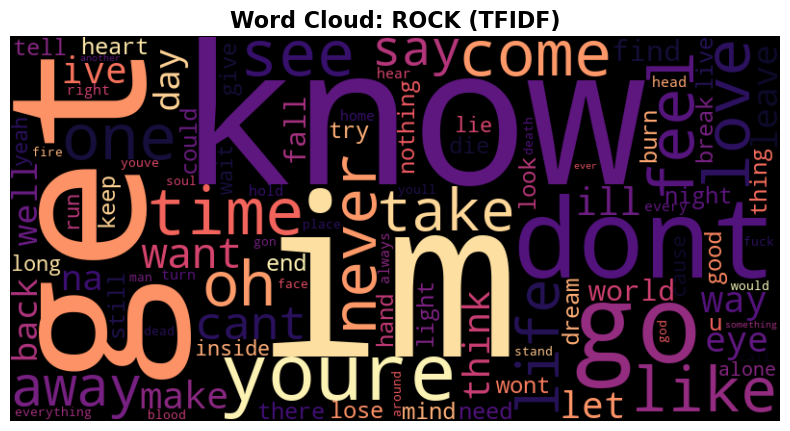

Word Cloud guardada: WC_ROCK_TFIDF.png
--------------------------------------------------



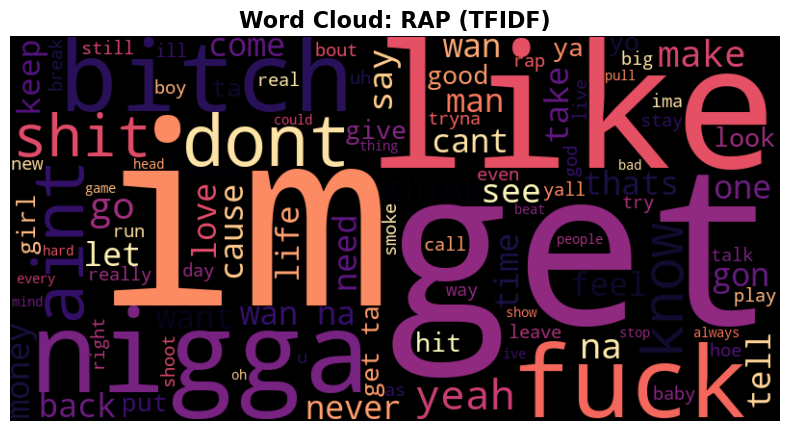

Word Cloud guardada: WC_RAP_TFIDF.png
--------------------------------------------------



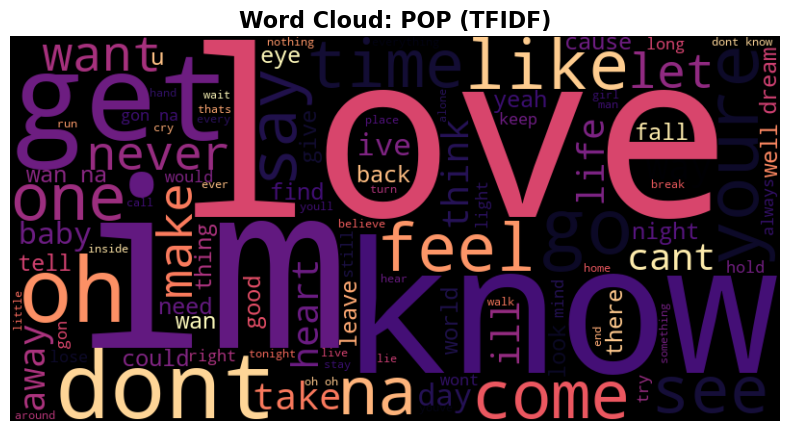

Word Cloud guardada: WC_POP_TFIDF.png
--------------------------------------------------



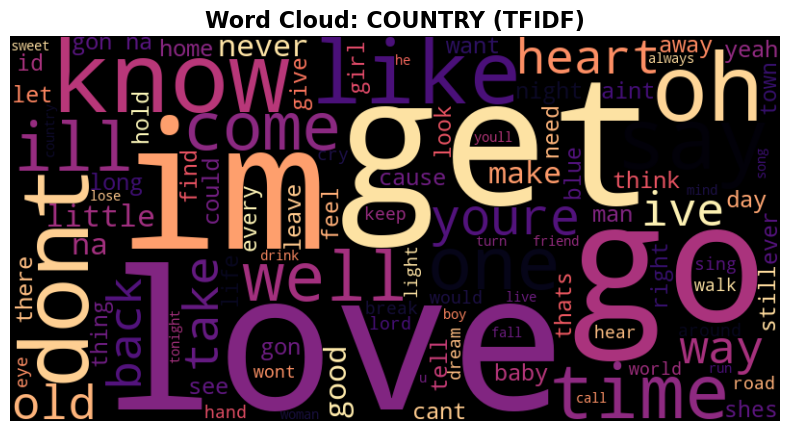

Word Cloud guardada: WC_COUNTRY_TFIDF.png
--------------------------------------------------



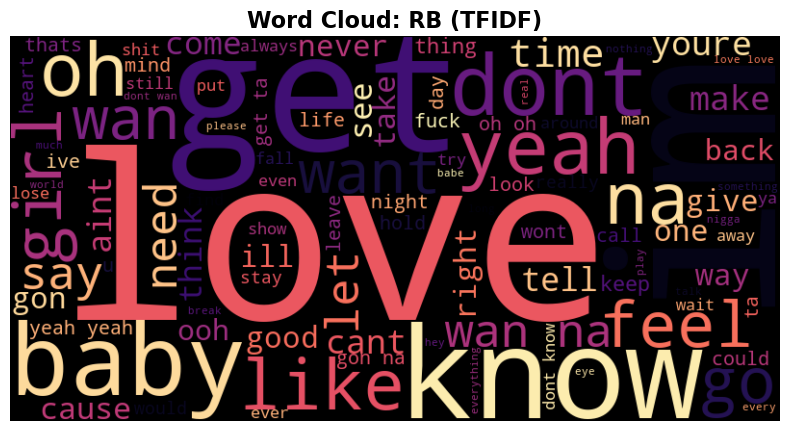

Word Cloud guardada: WC_RB_TFIDF.png
--------------------------------------------------



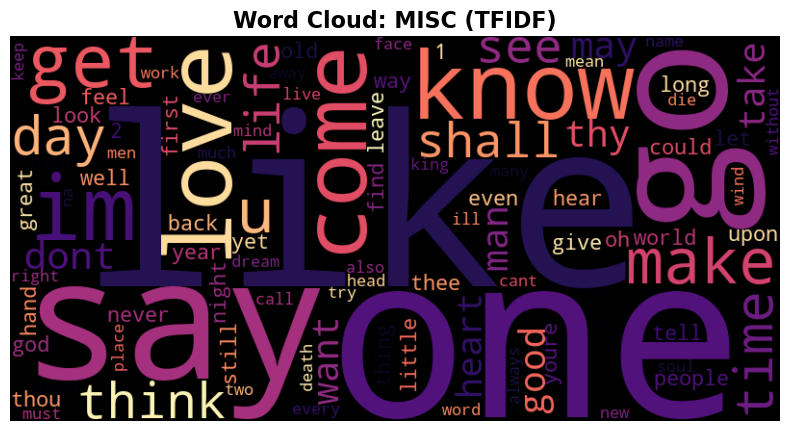

Word Cloud guardada: WC_MISC_TFIDF.png
--------------------------------------------------



In [26]:
from wordcloud import WordCloud

my_wc = WordCloud(width=800, height=400, background_color='black', max_words=100, colormap='magma')

genre_word_cloud_generator_and_show(
    folder_path="genre_word_clouds", 
    dataset=train_dataset, 
    wc=my_wc, 
    matrix=tfidf_matrix, 
    word_list=tfidf_word_list, 
    vectorisation="tfidf"
)